### 1. Import Dependencies

In [4]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)

dataset_location = os.getenv("RAW_DATASET_LOCATION")

In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### 2. Reading file

In [8]:
df = pd.read_csv(dataset_location)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 3. Advance Multivariate Analysis

#### 3.1 Correlation Heatmap for Numerical Features

see which financial variables move together

In [11]:
numerical_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
df[numerical_cols] = df[numerical_cols].apply(pd.to_numeric, errors='coerce')
print(df[numerical_cols].dtypes)

tenure              int64
MonthlyCharges    float64
TotalCharges      float64
dtype: object


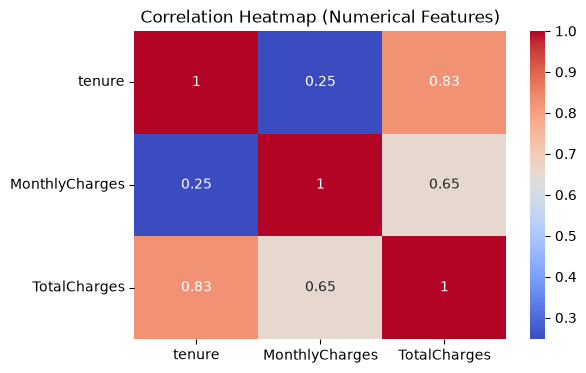

In [12]:
plt.figure(figsize=(6,4))
sns.heatmap(df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap (Numerical Features)")
plt.show()

#### 3.2 Churn vs. Contract × PaymentMethod (Interaction between 2 categorical features)

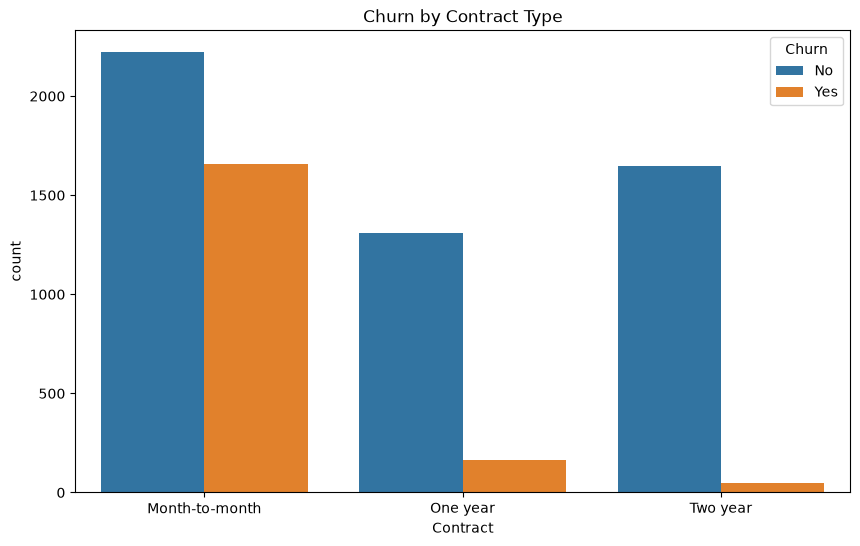

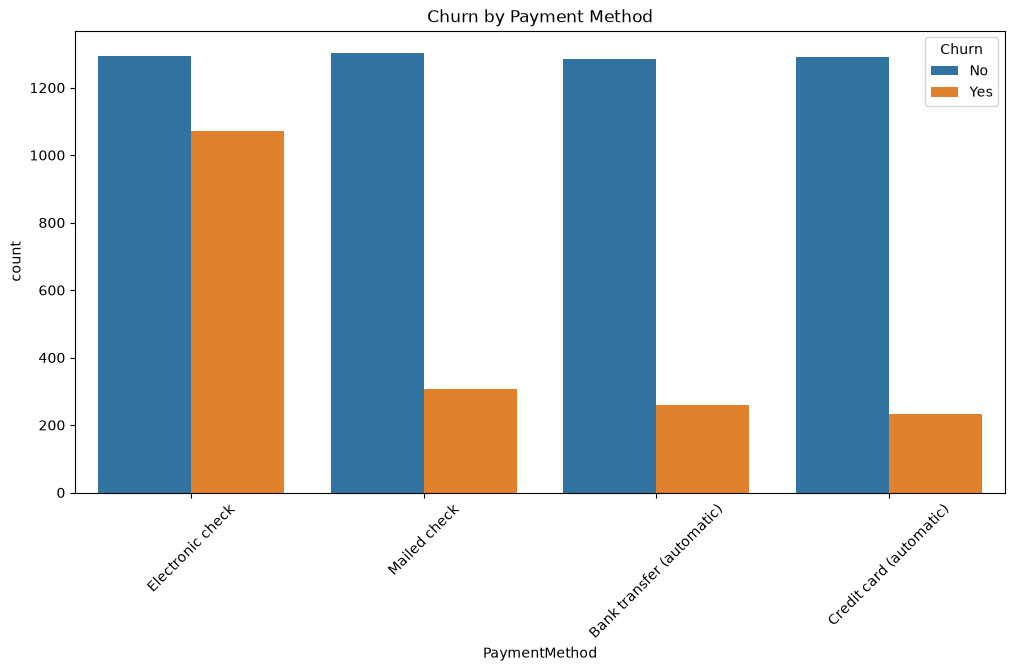

In [13]:
plt.figure(figsize=(10,6))
sns.countplot(x="Contract", hue="Churn", data=df)
plt.title("Churn by Contract Type")
plt.show()

plt.figure(figsize=(12,6))
sns.countplot(x="PaymentMethod", hue="Churn", data=df)
plt.title("Churn by Payment Method")
plt.xticks(rotation=45)
plt.show()

In [14]:
# Cross interaction: Contract × PaymentMethod
ct = pd.crosstab([df['Contract'], df['PaymentMethod']], df['Churn'], normalize="index") * 100
print(ct.round(2))

Churn                                        No    Yes
Contract       PaymentMethod                          
Month-to-month Bank transfer (automatic)  65.87  34.13
               Credit card (automatic)    67.22  32.78
               Electronic check           46.27  53.73
               Mailed check               68.42  31.58
One year       Bank transfer (automatic)  90.28   9.72
               Credit card (automatic)    89.70  10.30
               Electronic check           81.56  18.44
               Mailed check               93.18   6.82
Two year       Bank transfer (automatic)  96.63   3.37
               Credit card (automatic)    97.76   2.24
               Electronic check           92.26   7.74
               Mailed check               99.21   0.79


#### 3.3 Boxplots: Financial variables grouped by Churn

Churn distribution for financial features.

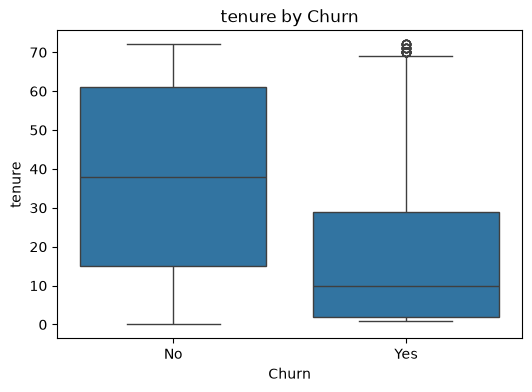

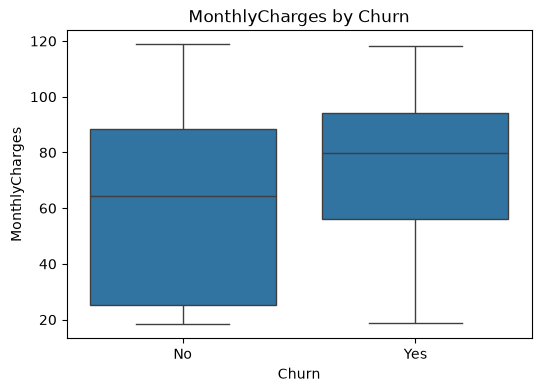

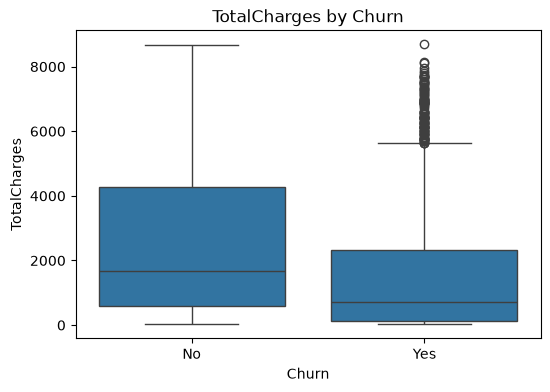

In [15]:
for col in ['tenure','MonthlyCharges','TotalCharges']:
    plt.figure(figsize=(6,4))
    sns.boxplot(x='Churn', y=col, data=df)
    plt.title(f"{col} by Churn")
    plt.show()

#### 3.3 Multivariate Pairplot (Financial vs. Churn hue)

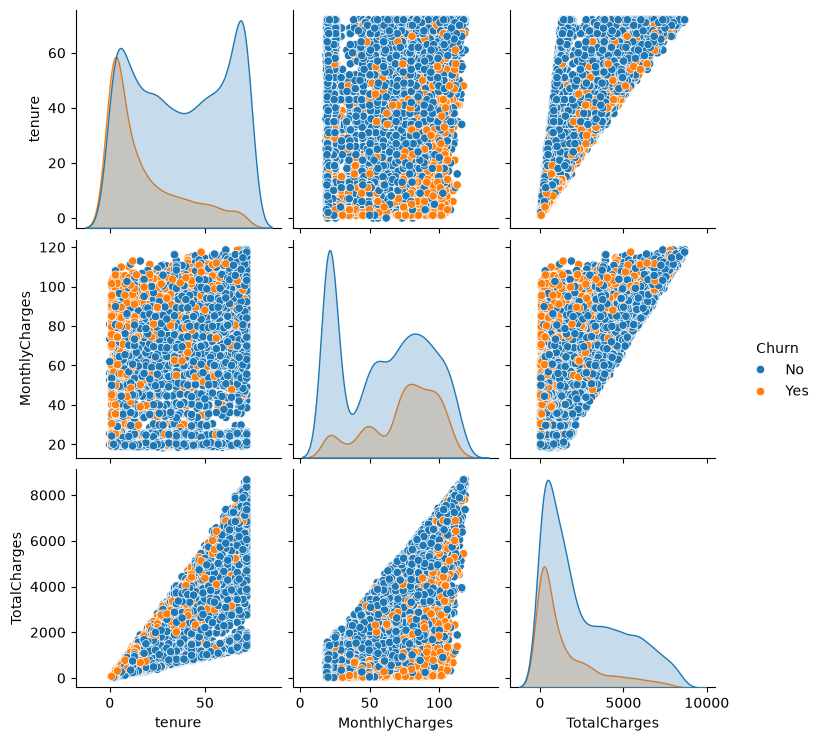

In [16]:
sns.pairplot(df[['tenure','MonthlyCharges','TotalCharges','Churn']], hue='Churn')
plt.show()

#### 3.4 Churn Rate by Contract × Tenure Segment

Bin tenure to see churn trends across both contract length & customer age.

In [17]:
df['tenure_group'] = pd.cut(df['tenure'], bins=[0,12,24,48,72], labels=['0-12','13-24','25-48','49-72'])

churn_rate = df.groupby(['Contract','tenure_group'])['Churn'].value_counts(normalize=True).unstack().fillna(0)*100
print(churn_rate.round(2))

Churn                            No    Yes
Contract       tenure_group               
Month-to-month 0-12           48.65  51.35
               13-24          62.28  37.72
               25-48          67.08  32.92
               49-72          73.98  26.02
One year       0-12           89.43  10.57
               13-24          91.88   8.12
               25-48          89.38  10.62
               49-72          87.07  12.93
Two year       0-12          100.00   0.00
               13-24         100.00   0.00
               25-48          97.81   2.19
               49-72          96.67   3.33
